# 13.4 USDA Food Database

## Mục đích
Mục đích chính của việc phân tích Cơ sở dữ liệu Thực phẩm USDA là để khám phá chi tiết hàm lượng dinh dưỡng của các loại thực phẩm được Bộ Nông nghiệp Hoa Kỳ công bố, qua đó xây dựng một hiểu biết sâu sắc về thành phần dinh dưỡng của chúng. Để đạt được điều này, dữ liệu cần được tái cấu trúc thành một định dạng bảng cho phép phân tích dinh dưỡng hiệu quả theo các nhóm thực phẩm lớn (food groups). Cuối cùng, phân tích này nhằm đánh giá các mối tương quan giữa các thành phần dinh dưỡng khác nhau, chẳng hạn như mối liên hệ giữa hàm lượng protein, chất béo (lipid) và năng lượng (energy), nhằm đưa ra những kết luận toàn diện về đặc tính dinh dưỡng của các nhóm thực phẩm.

## Mục tiêu
Mục tiêu tổng quát là chuyển đổi dữ liệu thô, phức tạp thành thông tin dinh dưỡng có giá trị để hỗ trợ nghiên cứu và khuyến nghị sức khỏe:

+ Khám phá Dinh dưỡng: Khám phá hàm lượng dinh dưỡng của các loại thực phẩm được USDA công bố để xác định các nguồn cung cấp chất dinh dưỡng cụ thể (ví dụ: thực phẩm giàu Protein, thấp Năng lượng).

+ Cấu trúc hóa Dữ liệu: Tạo cấu trúc dữ liệu phẳng (DataFrame) cho phép phân tích dinh dưỡng hiệu quả theo các nhóm thực phẩm lớn (food groups).

+ Đánh giá Tương quan: Đánh giá các mối tương quan giữa các chất dinh dưỡng (như protein, chất béo, năng lượng) để hiểu được cách các thành phần dinh dưỡng liên kết với nhau trong thực phẩm.

## Input
Dữ liệu thô JSON phức tạp của USDA Food Database. Sau khi xử lý, đầu vào được chuẩn hóa thành DataFrame Pandas (ndata) với các biến chính là group và description (tên chất dinh dưỡng), cùng với các giá trị hàm lượng.

## Output
các thông tin có ý nghĩa, bao gồm các giá trị Trung bình/Trung vị để xác định hàm lượng điển hình, các bảng xếp hạng thực phẩm có giá trị dinh dưỡng cực đại, các chỉ số Tương quan giữa các chất dinh dưỡng, và các Tỷ lệ Dinh dưỡng tổng hợp (như $E/P$) để đánh giá chất lượng và hỗ trợ cho các khuyến nghị dinh dưỡng.

Bộ Nông nghiệp Hoa Kỳ (USDA) cung cấp cơ sở dữ liệu thông tin dinh dưỡng trong thực phẩm. Lập trình viên Ashley Williams đã tạo ra một phiên bản của cơ sở dữ liệu này ở định dạng JSON.
File data có dạng:

In [578]:
[
    {
        "id": 1008,
        "description": "Cheese, caraway",
        "tags": [],
        "manufacturer": "",
        "group": "Dairy and Egg Products",
        "portions": [
            {
                "amount": 1,
                "unit": "oz",
                "grams": 28.35
            }
        ],
        "nutrients": [
            {
                "value": 25.18,
                "units": "g",
                "description": "Protein",
                "group": "Composition"
            },
            ...
        ]
    },
    ...
]

[{'id': 1008,
  'description': 'Cheese, caraway',
  'tags': [],
  'manufacturer': '',
  'group': 'Dairy and Egg Products',
  'portions': [{'amount': 1, 'unit': 'oz', 'grams': 28.35}],
  'nutrients': [{'value': 25.18,
    'units': 'g',
    'description': 'Protein',
    'group': 'Composition'},
   Ellipsis]},
 Ellipsis]

Từ điển thực phẩm chứa các thuộc tính cơ bản như id, description, manufacturer, và group (nhóm thực phẩm).

Có hai trường là danh sách lồng nhau (phân cấp dữ liệu):

+ portions chứa chi tiết khẩu phần ăn.

+ nutrients là một Danh sách các Từ điển con, chứa thông tin dinh dưỡng chi tiết. Mỗi Từ điển con trong danh sách mô tả một chất dinh dưỡng duy nhất.

Các khóa trong từ điển chất dinh dưỡng bao gồm value (hàm lượng), units (đơn vị), description (tên chất dinh dưỡng), và group (nhóm dinh dưỡng).

Cấu trúc nhiều lớp này yêu cầu kỹ thuật làm phẳng dữ liệu để phân tích bảng

## 13.4.1 Set up

### Import thư viện

In [579]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns


### Tạo thư mục images

In [580]:
import os

# 1. Định nghĩa đường dẫn và tên thư mục
folder_name = "images" 

# 2. Tạo thư mục
os.makedirs(folder_name, exist_ok=True) 

## 13.4.2 Xử lý dữ liệu

### Load database
Load database dưới dạng file JSON

In [581]:
import json
db = json.load(open("../datasets/usda_food/database.json"))
print("Số phần tử:", len(db))

Số phần tử: 6636


## Tái cấu trúc dữ liệu
Quá trình tái cấu trúc dữ liệu (data restructuring) là bước nền tảng và quan trọng nhất trong việc phân tích bộ dữ liệu USDA Food Database. Nó cần thiết vì dữ liệu ban đầu nằm ở định dạng JSON phân cấp (nested JSON), khiến các thuộc tính của chất dinh dưỡng (như value và units) bị lồng sâu bên trong mỗi bản ghi thực phẩm.

Mục tiêu của tái cấu trúc là chuyển dữ liệu từ cấu trúc phân cấp sang cấu trúc phẳng (flat structure), dễ dàng truy vấn và phân tích bằng Pandas.

### Trích Xuất và Làm Phẳng

Tạo DataFrame con từ dữ liệu gốc, đặt tên là info.
Lấy danh sách thông tin thực phẩm bao gồm tên thực phẩm, nhóm, ID và nhà sản xuất:

In [582]:
info_keys = ["description", "group", "id", "manufacturer"]
info = pd.DataFrame(db, columns=info_keys)
info.head()

,description,group,id,manufacturer
0,"Cheese, caraway",Dairy and Egg Products,1008,
1,"Cheese, cheddar",Dairy and Egg Products,1009,
2,"Cheese, edam",Dairy and Egg Products,1018,
3,"Cheese, feta",Dairy and Egg Products,1019,
4,"Cheese, mozzarella, part skim milk",Dairy and Egg Products,1028,


Chuyển đổi từng danh sách chất dinh dưỡng của thực phẩm thành một DataFrame.

Gắn nhãn: một cột id duy nhất của thực phẩm được lấy ra và gán cho tất cả các hàng trong DataFrame nhỏ (fnuts["id"] = rec["id"]). Việc này là tối quan trọng để duy trì mối liên kết giữa chất dinh dưỡng chi tiết và thực phẩm gốc. Sau đó, chúng có thể được nối với nhau bằng hàm concat:

In [583]:
nutrients = []
for rec in db:
    fnuts = pd.DataFrame(rec["nutrients"])
    fnuts["id"] = rec["id"]
    nutrients.append(fnuts)
nutrients = pd.concat(nutrients, ignore_index=True)

nutrients

,value,units,description,group,id
0,25.180,g,Protein,Composition,1008
1,29.200,g,Total lipid (fat),Composition,1008
2,3.060,g,"Carbohydrate, by difference",Composition,1008
3,3.280,g,Ash,Other,1008
4,376.000,kcal,Energy,Energy,1008
...,...,...,...,...,...
389350,0.000,mcg,"Vitamin B-12, added",Vitamins,43546
389351,0.000,mg,Cholesterol,Other,43546
389352,0.072,g,"Fatty acids, total saturated",Other,43546
389353,0.028,g,"Fatty acids, total monounsaturated",Other,43546


### Xử lý dữ liệu trùng

In [584]:
# Kiểm tra dữ liệu trùng
print("Số dữ liệu bị trùng:", nutrients.duplicated().sum())

Số dữ liệu bị trùng: 14179


In [585]:
# Tiến hành xử lý bằng drop_duplicates()
nutrients = nutrients.drop_duplicates()

# kiểm tra lại
print("Số dữ liệu bị trùng:", nutrients.duplicated().sum())

Số dữ liệu bị trùng: 0


Vì cả 2 DataFrame đều chứa cột "description" và "group", nên sẽ đổi tên để dễ dàng phân biệt.

In [586]:
col_mapping = {"description" : "food", "group" : "fgroup"}
# Đổi tên cột
info = info.rename(columns=col_mapping, copy=False)

info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6636 entries, 0 to 6635
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   food          6636 non-null   object
 1   fgroup        6636 non-null   object
 2   id            6636 non-null   int64 
 3   manufacturer  5195 non-null   object
dtypes: int64(1), object(3)
memory usage: 207.5+ KB


In [587]:
# Trên DataFrame gốc
col_mapping = {"description" : "nutrient", "group" : "nutgroup"}
# Đổi tên cột
nutrients = nutrients.rename(columns=col_mapping, copy=False)

nutrients.info()


<class 'pandas.core.frame.DataFrame'>
Index: 375176 entries, 0 to 389354
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   value     375176 non-null  float64
 1   units     375176 non-null  object 
 2   nutrient  375176 non-null  object 
 3   nutgroup  375176 non-null  object 
 4   id        375176 non-null  int64  
dtypes: float64(1), int64(1), object(3)
memory usage: 17.2+ MB


### Tổng Hợp và Chuẩn Hóa
Tiến hành merge dữ liệu từ 2 DataFrame thông qua cột id:

In [588]:
ndata = pd.merge(nutrients, info, on="id")

ndata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375176 entries, 0 to 375175
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   value         375176 non-null  float64
 1   units         375176 non-null  object 
 2   nutrient      375176 non-null  object 
 3   nutgroup      375176 non-null  object 
 4   id            375176 non-null  int64  
 5   food          375176 non-null  object 
 6   fgroup        375176 non-null  object 
 7   manufacturer  293054 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 22.9+ MB


In [589]:
ndata.head(10)

,value,units,nutrient,nutgroup,id,food,fgroup,manufacturer
0,25.18,g,Protein,Composition,1008,"Cheese, caraway",Dairy and Egg Products,
1,29.20,g,Total lipid (fat),Composition,1008,"Cheese, caraway",Dairy and Egg Products,
2,3.06,g,"Carbohydrate, by difference",Composition,1008,"Cheese, caraway",Dairy and Egg Products,
3,3.28,g,Ash,Other,1008,"Cheese, caraway",Dairy and Egg Products,
4,376.00,kcal,Energy,Energy,1008,"Cheese, caraway",Dairy and Egg Products,
5,39.28,g,Water,Composition,1008,"Cheese, caraway",Dairy and Egg Products,
6,1573.00,kJ,Energy,Energy,1008,"Cheese, caraway",Dairy and Egg Products,
7,0.00,g,"Fiber, total dietary",Composition,1008,"Cheese, caraway",Dairy and Egg Products,
8,673.00,mg,"Calcium, Ca",Elements,1008,"Cheese, caraway",Dairy and Egg Products,
9,0.64,mg,"Iron, Fe",Elements,1008,"Cheese, caraway",Dairy and Egg Products,


## 13.4.3 Phân tích dữ liệu
### Câu hỏi nghiên cứu
#### Phân tích mô tả
Trong phân này chúng ta sẽ tìm hiểu về các câu hỏi sau:
+ Trung bình năng lượng (kcal) của từng nhóm thực phẩm là bao nhiêu? 
+ Loại thực phẩm nào chứa protein cao nhất trong nhóm “Dairy and Egg Products”?
+ Nhóm nào có độ đa dạng dinh dưỡng cao nhất (nhiều loại chất khác nhau)?

#### Trung bình năng lượng (kcal) của từng nhóm thực phẩm là bao nhiêu?

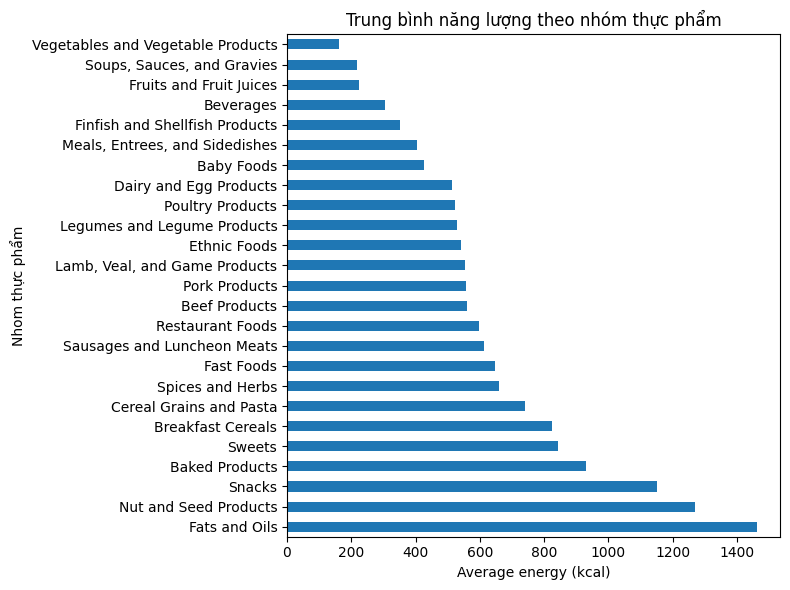

In [590]:
ndata[ndata['nutrient']=="Energy"].groupby('fgroup')['value'].mean().sort_values(ascending=False).plot(kind='barh', figsize=(8,6))
plt.xlabel("Average energy (kcal)")
plt.ylabel("Nhom thực phẩm")
plt.title("Trung bình năng lượng theo nhóm thực phẩm")
plt.tight_layout()
plt.savefig("images/average_energy_per_food_group.png")

Nhóm giàu năng lượng nhất:

+ Chất béo và Dầu (Fats and Oils) có mức năng lượng trung bình cao nhất, vượt trội so với tất cả các nhóm khác (hơn 1400 kcal). Điều này là do chất béo là chất cung cấp nhiều năng lượng nhất.

+ Theo sau là các nhóm như Các loại hạt (Nut and Seed Products), Đồ ăn vặt (Snacks), Đồ ngọt (Sweets) và Bánh nướng (Baked Products). Đây đều là những nhóm thực phẩm thường chứa nhiều chất béo và đường.

Nhóm ít năng lượng nhất:

+ Rau và các sản phẩm từ rau (Vegetables and Vegetable Products) có mức năng lượng trung bình thấp nhất.

+ Các nhóm khác cũng có ít năng lượng bao gồm Súp và nước sốt (Soups, Sauces, and Gravies), Trái cây và nước ép (Fruits and Fruit Juices), và Đồ uống (Beverages). Các loại thực phẩm này thường chứa nhiều nước và chất xơ.

> → Điều này sát với thực tế vì ăn thực phẩm có nhiều chất béo hay đồ ngọt sẽ nhanh no hơn các loại từ rau hay đồ uống.

#### Loại thực phẩm nào chứa protein cao nhất trong nhóm “Dairy and Egg Products”?


C:\Users\biedu\AppData\Local\Temp\ipykernel_11704\4227063141.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




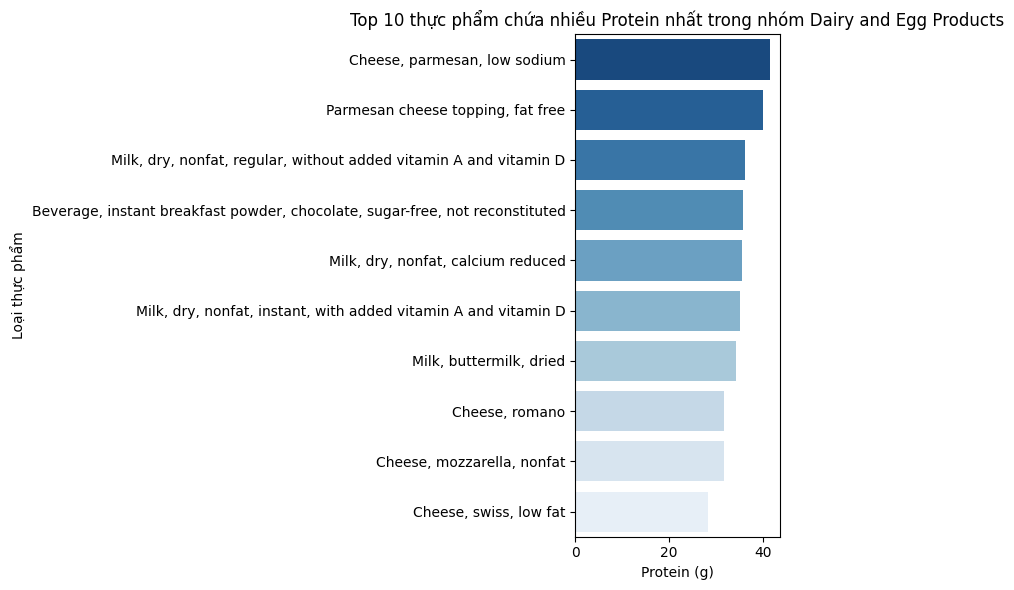

In [591]:
protein_data = ndata[(ndata['fgroup']=="Dairy and Egg Products") & (ndata['nutrient']=="Protein")]
top_10 = protein_data.sort_values(by='value', ascending=False).head(10)
plt.figure(figsize=(8, 6))
sns.barplot(data=top_10, y='food', x='value', palette='Blues_r')
plt.xlabel('Protein (g)')
plt.ylabel('Loại thực phẩm')
plt.title('Top 10 thực phẩm chứa nhiều Protein nhất trong nhóm Dairy and Egg Products')
plt.tight_layout()
plt.show()

Hàm lượng protein dao động khoảng từ 30–40g/100g, trong đó “Cheese, parmesan, low sodium” có giá trị cao nhất, vượt trội hơn các sản phẩm khác trong cùng nhóm.

→ Các sản phẩm chế biến từ sữa, đặc biệt là phô mai và sữa bột, là nguồn cung cấp protein phong phú, phù hợp cho chế độ ăn cần nhiều đạm như người luyện tập thể thao hoặc cần bổ sung năng lượng cao.

#### Nhóm nào có độ đa dạng dinh dưỡng cao nhất (nhiều loại chất khác nhau)?

In [592]:
# Đếm số lượng loại chất dinh dưỡng (nutrient) khác nhau trong từng nhóm thực phẩm (fgroup)
diversity = ndata.groupby('fgroup')['nutrient'].nunique().reset_index()

# Đổi tên cột cho dễ hiểu
diversity.columns = ['Food Group', 'Unique Nutrients Count']

# Sắp xếp giảm dần để nhóm đa dạng nhất nằm trên cùng
diversity_sorted = diversity.sort_values(by='Unique Nutrients Count', ascending=False)

# Lấy nhóm có độ đa dạng dinh dưỡng cao nhất
most_diverse = diversity_sorted.iloc[0]
most_diverse

Food Group                Vegetables and Vegetable Products
Unique Nutrients Count                                   94
Name: 24, dtype: object

Bây giờ chúng ta có thể tạo biểu đồ giá trị trung bình theo nhóm thực phẩm và loại chất dinh dưỡng như sau:

<Axes: ylabel='fgroup'>

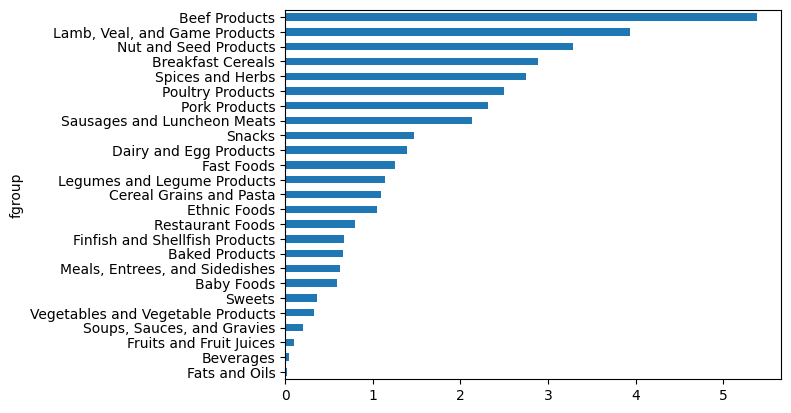

In [593]:
result = ndata.groupby(["nutrient", "fgroup"])["value"].quantile(0.5)
pic_1 = result["Zinc, Zn"].sort_values().plot(kind="barh")

pic_1.figure.savefig("images/Calo.png")
pic_1
